In [ ]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
import os
import random
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Audio
from tqdm import TqdmWarning, tqdm, trange

warnings.filterwarnings("ignore", category=TqdmWarning)

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

from src.dataset import (
    ALL_CLASSES,
    CORE_CLASSES,
    ID2LABEL,
    LABEL2ID,
    SAMPLE_LENGTH,
    SpeechCommandsDatasetFactory,
)

sns.set_theme(style="whitegrid")

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# All plots in this notebook are based on the same STFT parameters.
# Keeping these values fixed is important because frequency-bin indices only make sense
# when every spectrogram uses the same sample rate and FFT configuration.
SAMPLE_RATE = 16_000
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 128
MFCC_COUNT = 13

In [ ]:
factory = SpeechCommandsDatasetFactory("../train")

# Use the complete dataset in one object instead of keeping separate train/validation/test datasets.
# Exclude silence samples for better anomaly detection.
dataset = factory.all(add_silence=False, skip_anomalies=False)

print(f"Samples: {len(dataset):,}")

Samples: 26,035


,count
label,
yes,2377
no,2375
up,2375
down,2359
left,2353
right,2367
on,2367
off,2357
stop,2380


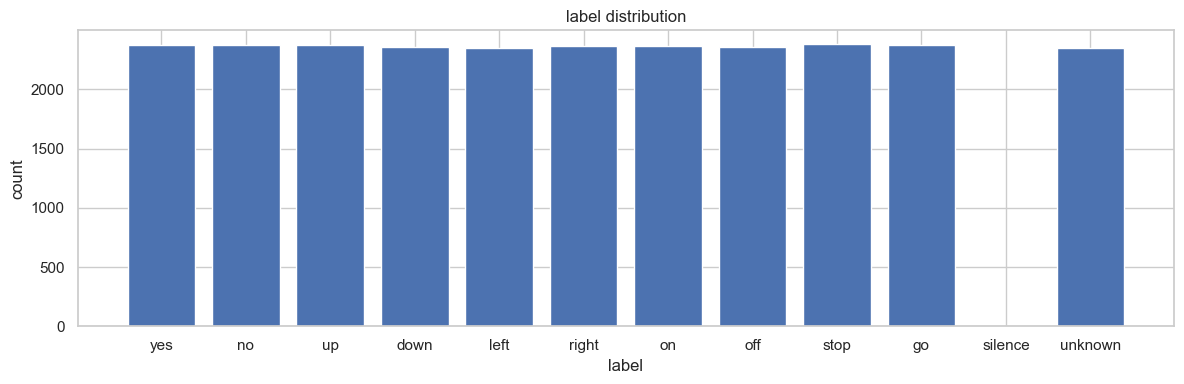

In [ ]:
# The current Dataset already stores integer labels, so no LabelEncoder or manual label list is needed.
label_counts: pd.DataFrame = (
    pd.DataFrame(dataset.samples)
    .assign(label=lambda frame: frame["label"].map(ID2LABEL))
    .groupby("label")
    .size()
    .reindex(ALL_CLASSES, fill_value=0)
    .rename("count")
    .to_frame()
)

display(label_counts)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(label_counts.index, label_counts["count"])
ax.set_title("label distribution")
ax.set_xlabel("label")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

In [5]:
def sample_indices_for_class(class_name: str):
    """Return indices in the complete Dataset for one class."""
    label = LABEL2ID[class_name]
    return [i for i, sample in enumerate(dataset.samples) if sample["label"] == label]


def wave_path_indices_for_class(class_name: str):
    """Return Dataset indices whose samples are backed by real WAV files."""
    label = LABEL2ID[class_name]
    return [
        i
        for i, sample in enumerate(dataset.samples)
        if sample["label"] == label and sample["path"] is not None
    ]


def load_fixed_wave(path: Path, sr: int = SAMPLE_RATE):
    """Load one WAV file with librosa and force the same duration used by the Dataset."""
    y, loaded_sr = librosa.load(path, sr=sr, mono=True)
    y = librosa.util.fix_length(y, size=SAMPLE_LENGTH)
    return y.astype(np.float32), loaded_sr


def load_dataset_wave(index: int):
    """Load a sample through the current Dataset implementation.

    This also supports generated `silence` samples, whose sample path is None.
    """
    item = dataset[index]
    return item["speech"].squeeze(0).numpy().astype(np.float32), SAMPLE_RATE


def dataset_file(index: int):
    """Get the original WAV path for a Dataset sample that has one."""
    path = dataset.samples[index]["path"]
    if path is None:
        raise ValueError(
            "This Dataset sample is generated silence and has no WAV path."
        )
    return Path(path)


def mean_spectrum(y: np.ndarray, sr: int = SAMPLE_RATE):
    """Compute the mean magnitude spectrum over STFT frames using librosa."""
    stft = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH, center=False)
    magnitude = np.abs(stft)
    return librosa.fft_frequencies(sr=sr, n_fft=N_FFT), magnitude.mean(axis=1)


def power_spectrogram(y: np.ndarray, sr: int = SAMPLE_RATE):
    """Return a power spectrogram and its frequency/time axes."""
    power = (
        np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH, center=False)) ** 2
    )
    freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)
    times = librosa.times_like(power, sr=sr, hop_length=HOP_LENGTH, n_fft=N_FFT)
    return freqs, times, power

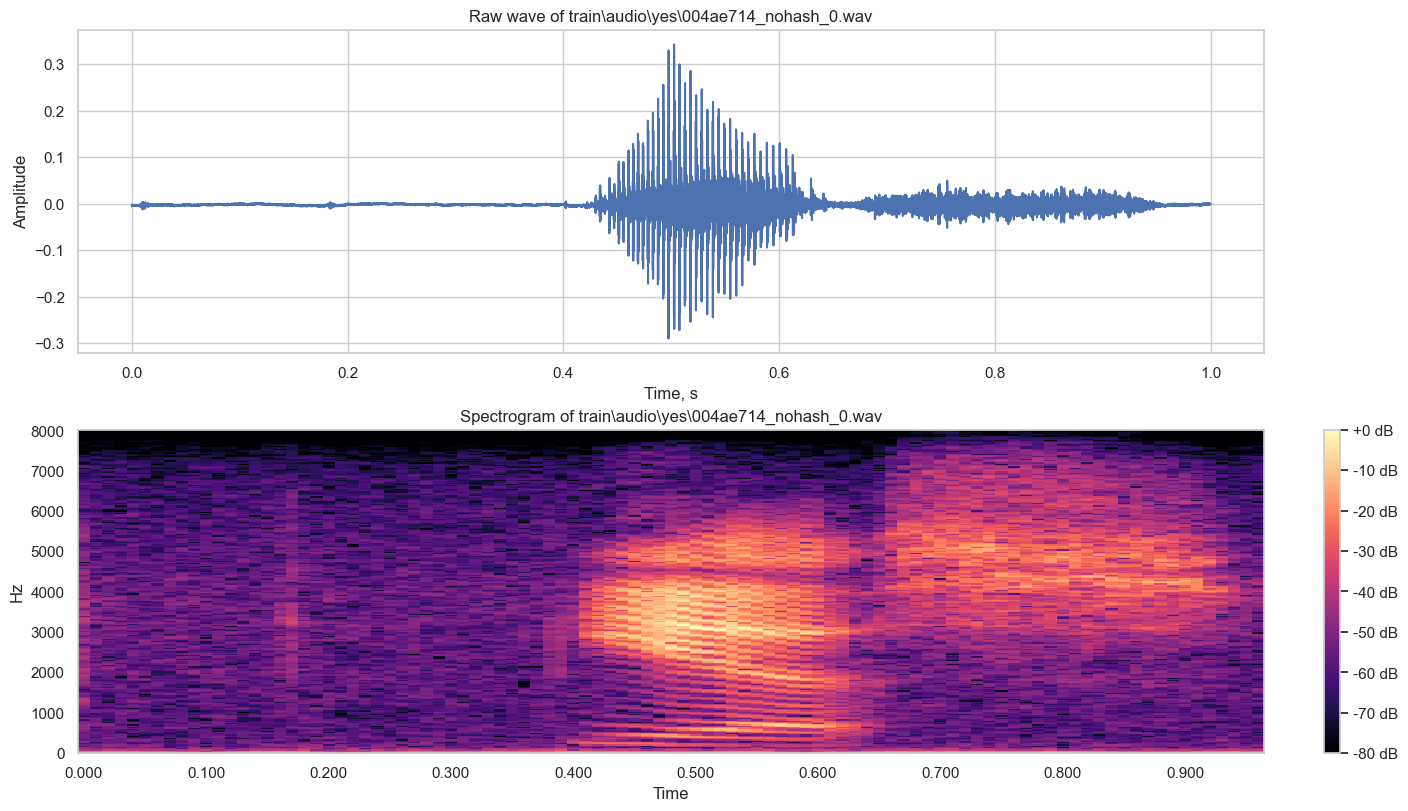

File: train\audio\yes\004ae714_nohash_0.wav


In [6]:
# Select one real `yes` recording from the complete Dataset.
yes_indices = wave_path_indices_for_class("yes")
yes_index = yes_indices[0]
yes_path = dataset_file(yes_index)
yes_wave, yes_sr = load_dataset_wave(yes_index)

# A time-domain waveform is useful for seeing duration, amplitude and silence around the spoken word.
time = np.arange(len(yes_wave)) / yes_sr

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
axes[0].plot(time, yes_wave)
axes[0].set_title(f"Raw wave of {yes_path}")
axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Amplitude")

D = librosa.amplitude_to_db(
    np.abs(librosa.stft(yes_wave, n_fft=N_FFT, hop_length=HOP_LENGTH, center=False)),
    ref=np.max,
)
librosa.display.specshow(
    D, sr=yes_sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="hz", ax=axes[1]
)
axes[1].set_title(f"Spectrogram of {yes_path}")
fig.colorbar(axes[1].collections[0], ax=axes[1], format="%+2.0f dB")
plt.show()

print(f"File: {yes_path}")
display(Audio(yes_wave, rate=yes_sr))

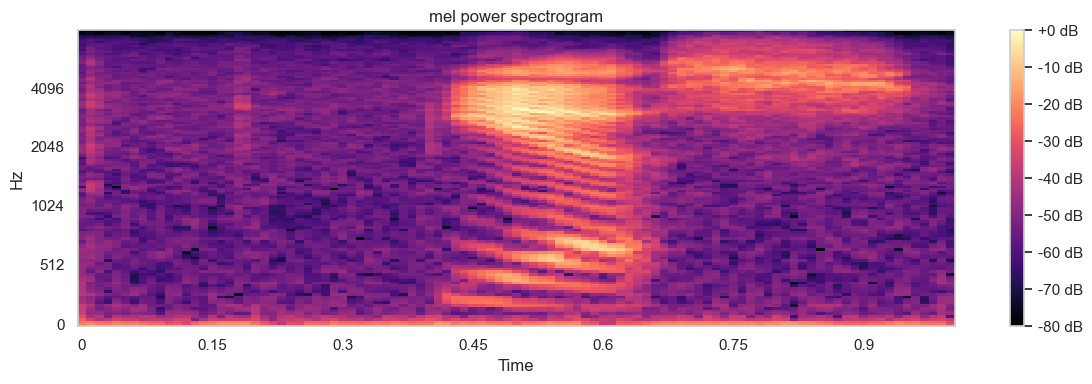

In [7]:
# Mel power spectrogram compresses the linear-frequency spectrum into perceptual Mel bands.
mel_power = librosa.feature.melspectrogram(
    y=yes_wave,
    sr=yes_sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0,
)
mel_db = librosa.power_to_db(mel_power, ref=np.max)

fig, ax = plt.subplots(figsize=(12, 4))
img = librosa.display.specshow(
    mel_db,
    sr=yes_sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax,
)
ax.set_title("mel power spectrogram")
fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()

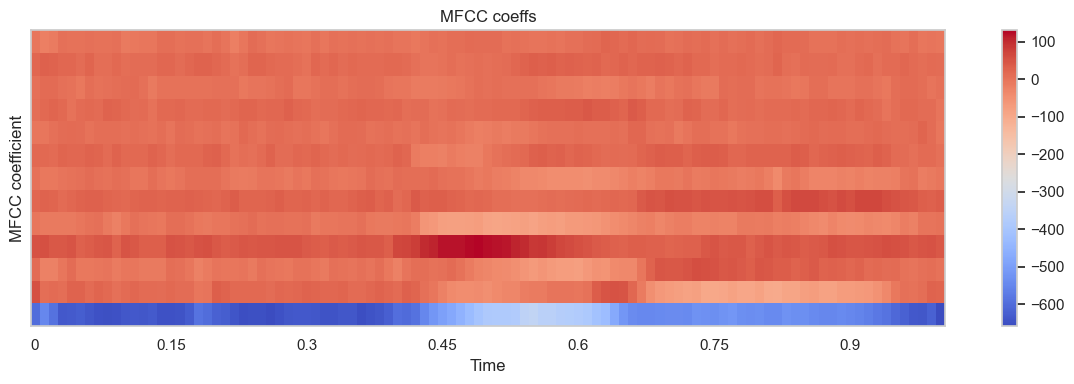

In [8]:
# librosa computes MFCCs directly from the waveform, including the usual Mel/filter-bank and DCT steps.
mfcc = librosa.feature.mfcc(
    y=yes_wave,
    sr=yes_sr,
    n_mfcc=MFCC_COUNT,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
)

fig, ax = plt.subplots(figsize=(12, 4))
img = librosa.display.specshow(
    mfcc,
    x_axis="time",
    ax=ax,
    sr=yes_sr,
    hop_length=HOP_LENGTH,
)
ax.set_title("MFCC coeffs")
ax.set_ylabel("MFCC coefficient")
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

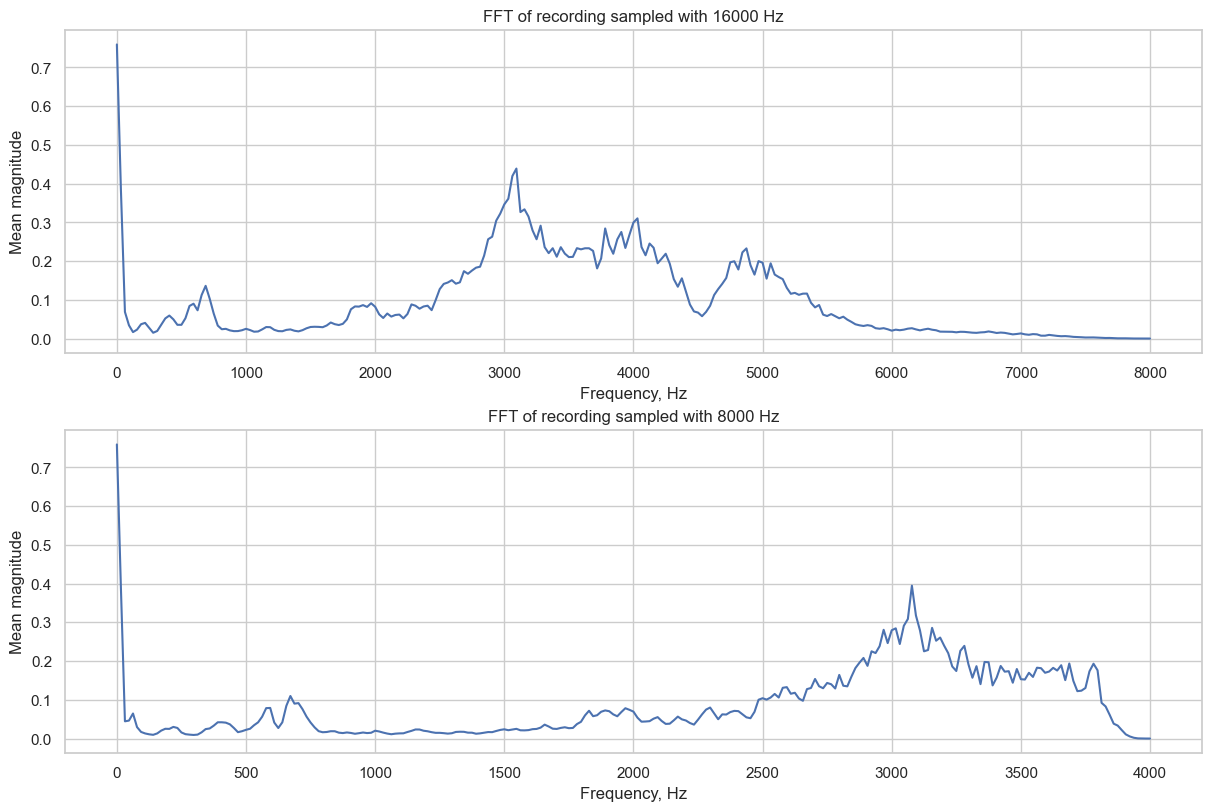

In [9]:
# Compare the same recording at its original sample rate and after resampling to 8 kHz.
# The 8 kHz version cannot contain frequencies above its Nyquist frequency (4 kHz).
y8 = librosa.resample(yes_wave, orig_sr=yes_sr, target_sr=8_000)

freqs = librosa.fft_frequencies(sr=yes_sr, n_fft=N_FFT)
fft_original = np.abs(
    librosa.stft(yes_wave, n_fft=N_FFT, hop_length=HOP_LENGTH, center=False)
).mean(axis=1)

freqs_8k = librosa.fft_frequencies(sr=8_000, n_fft=N_FFT)
fft_8k = np.abs(
    librosa.stft(y8, n_fft=N_FFT, hop_length=HOP_LENGTH, center=False)
).mean(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
axes[0].plot(freqs, fft_original)
axes[0].set_title(f"FFT of recording sampled with {yes_sr} Hz")
axes[0].set_xlabel("Frequency, Hz")
axes[0].set_ylabel("Mean magnitude")

axes[1].plot(freqs_8k, fft_8k)
axes[1].set_title("FFT of recording sampled with 8000 Hz")
axes[1].set_xlabel("Frequency, Hz")
axes[1].set_ylabel("Mean magnitude")
plt.show()

display(Audio(y8, rate=8_000))

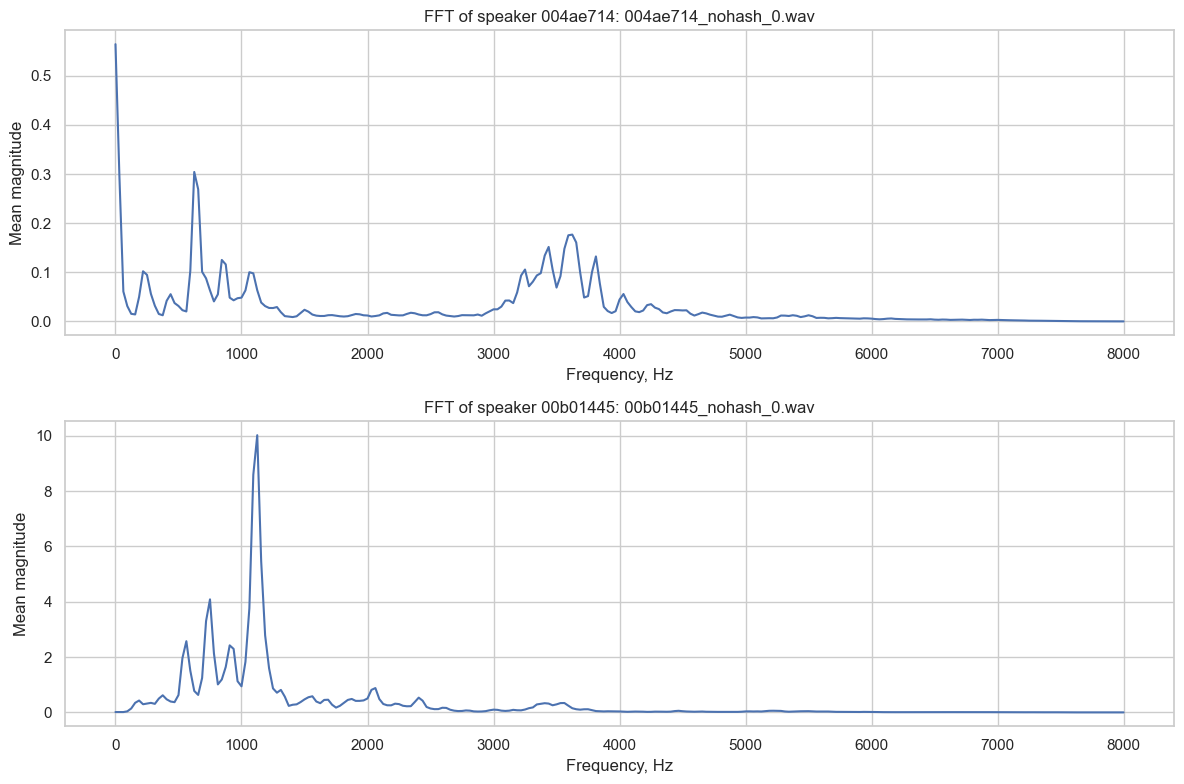

Recording: train\audio\on\004ae714_nohash_0.wav


Recording: train\audio\on\00b01445_nohash_0.wav


In [10]:
# Speaker identity is encoded in the standard Speech Commands filename prefix.
# Pick two different speakers saying the same word so the spectra can be compared without changing the command.
on_indices = wave_path_indices_for_class("on")
by_speaker = {}

for index in on_indices:
    path = dataset_file(index)
    speaker = path.stem.split("_")[0]
    by_speaker.setdefault(speaker, index)
    if len(by_speaker) >= 2:
        break

speaker_samples = list(by_speaker.items())[:2]

fig, axes = plt.subplots(
    len(speaker_samples), 1, figsize=(12, 4 * len(speaker_samples)), squeeze=False
)
for ax, (speaker, index) in zip(axes[:, 0], speaker_samples):
    wave, sr = load_dataset_wave(index)
    freq_axis, spectrum = mean_spectrum(wave, sr)
    ax.plot(freq_axis, spectrum)
    ax.set_title(f"FFT of speaker {speaker}: {dataset_file(index).name}")
    ax.set_xlabel("Frequency, Hz")
    ax.set_ylabel("Mean magnitude")

plt.tight_layout()
plt.show()

for _, index in speaker_samples:
    print(f"Recording: {dataset_file(index)}")
    display(Audio(dataset[index]["speech"].squeeze(0).numpy(), rate=SAMPLE_RATE))

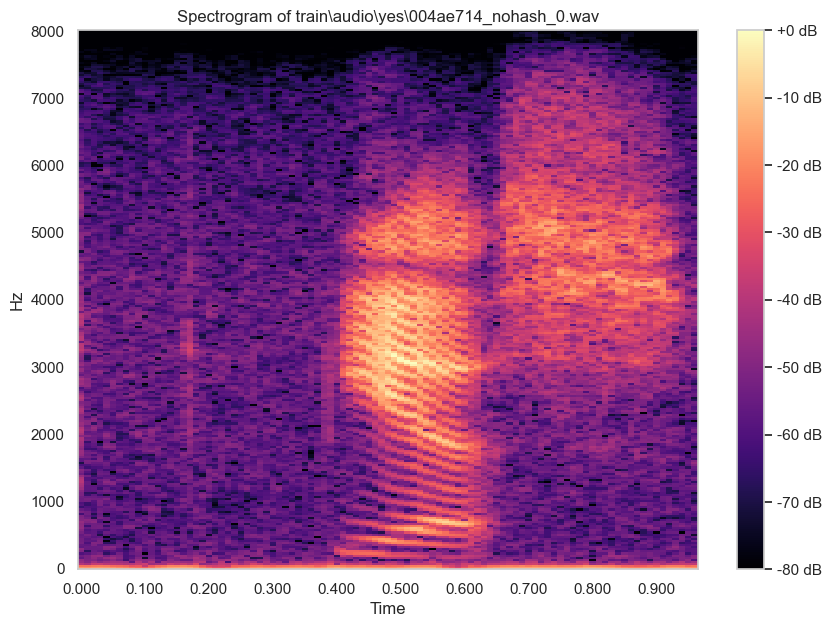

In [11]:
# Show the spectrogram of the selected `yes` recording separately from the combined waveform plot.
freqs_yes, times_yes, power_yes = power_spectrogram(yes_wave, yes_sr)
spec_yes_db = librosa.power_to_db(power_yes, ref=np.max)

fig, ax = plt.subplots(figsize=(10, 7))
img = librosa.display.specshow(
    spec_yes_db,
    sr=yes_sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="hz",
    ax=ax,
)
ax.set_title(f"Spectrogram of {yes_path}")
fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.show()

In [12]:
# Compute mean FFT and mean spectrogram for every core command.
# The complete Dataset may contain thousands of recordings per class, so we accumulate sums
# instead of storing every spectrogram in memory at once.
mean_fft_results = {}
mean_spec_results = {}

for class_name in CORE_CLASSES:
    indices = wave_path_indices_for_class(class_name)
    fft_sum = None
    spec_sum = None
    count = 0
    freq_axis = None
    time_axis = None

    for index in tqdm(indices, desc=class_name):
        wave, sr = load_dataset_wave(index)
        freq_axis, spectrum = mean_spectrum(wave, sr)
        _, _, power = power_spectrogram(wave, sr)

        if fft_sum is None:
            fft_sum = np.zeros_like(spectrum, dtype=np.float64)
            spec_sum = np.zeros_like(power, dtype=np.float64)
            time_axis = librosa.times_like(
                power, sr=sr, hop_length=HOP_LENGTH, n_fft=N_FFT
            )

        fft_sum += spectrum
        spec_sum += power
        count += 1

    mean_fft_results[class_name] = (freq_axis, fft_sum / count)
    mean_spec_results[class_name] = (
        time_axis,
        librosa.power_to_db(spec_sum / count, ref=np.max),
    )

go: 100%|██████████| 2372/2372 [00:02<00:00, 803.81it/s]


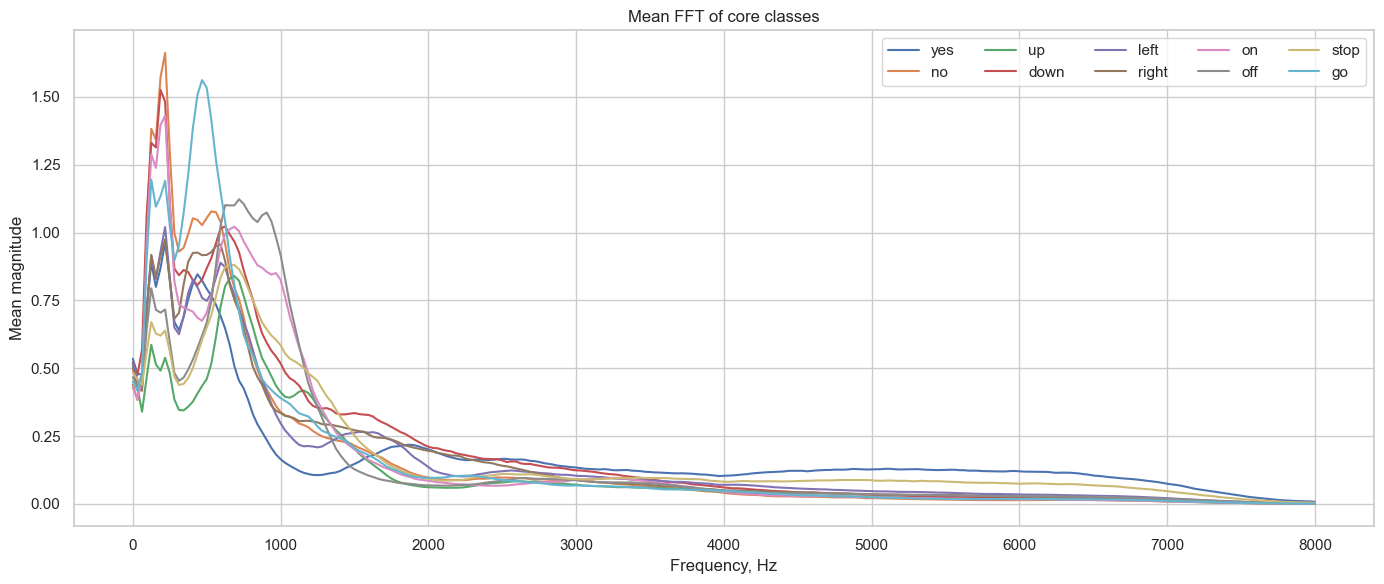

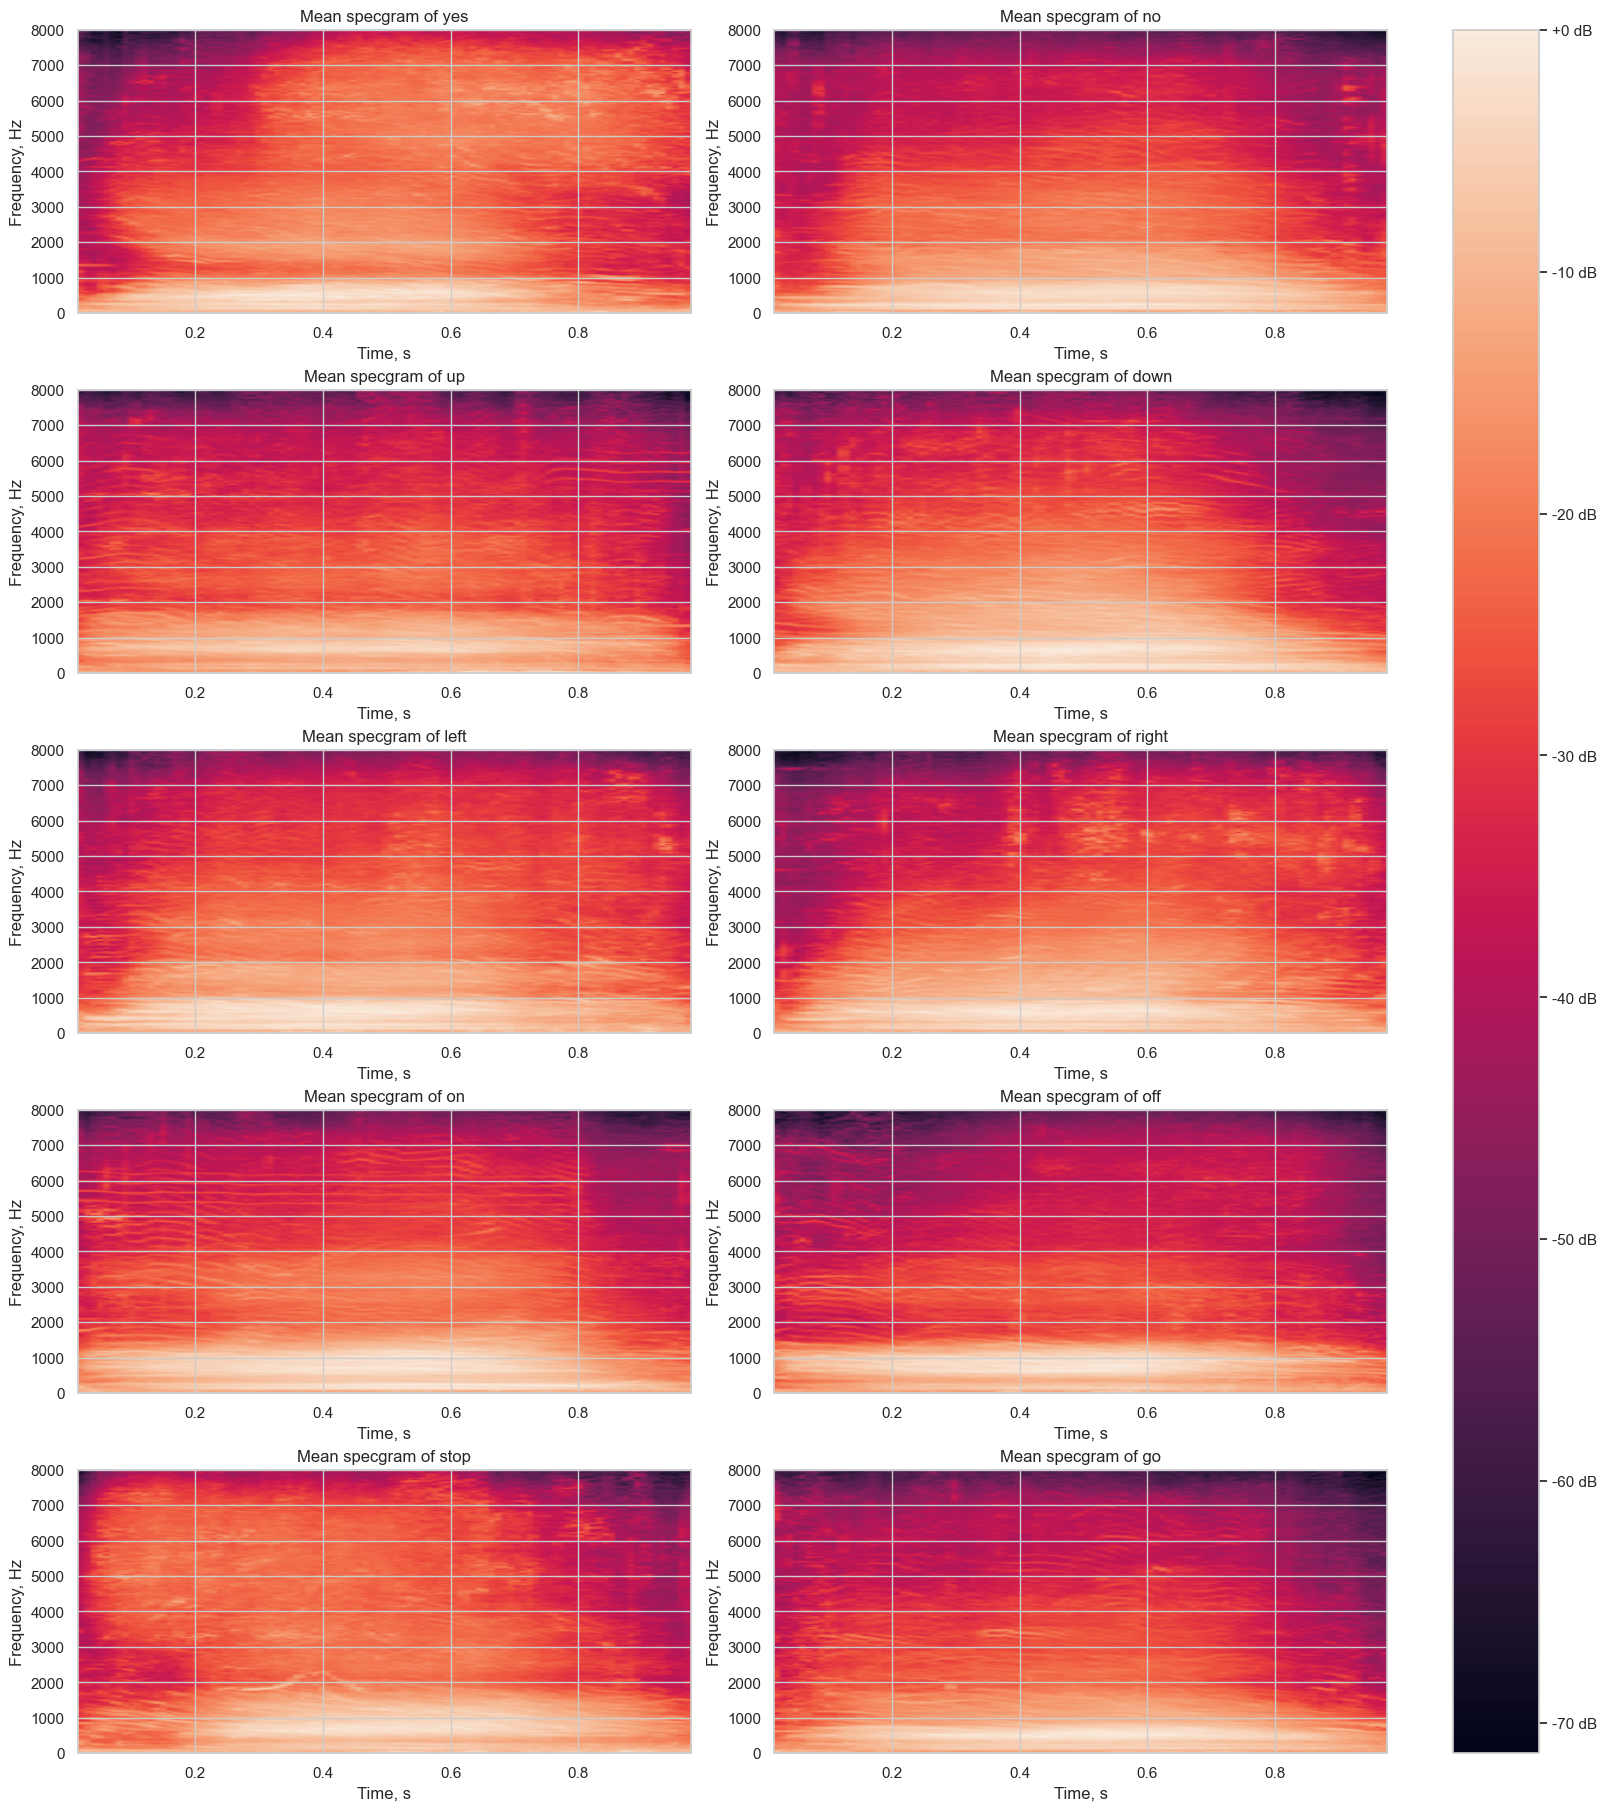

In [13]:
# Plot the aggregate FFTs together to make class-specific spectral differences visible.
fig, ax = plt.subplots(figsize=(14, 6))
for class_name in CORE_CLASSES:
    freq_axis, spectrum = mean_fft_results[class_name]
    ax.plot(freq_axis, spectrum, label=class_name)
ax.set_title("Mean FFT of core classes")
ax.set_xlabel("Frequency, Hz")
ax.set_ylabel("Mean magnitude")
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

# Show one mean spectrogram for every core class.
fig, axes = plt.subplots(5, 2, figsize=(16, 18), constrained_layout=True)
for ax, class_name in zip(axes.ravel(), CORE_CLASSES):
    time_axis, mean_spec_db = mean_spec_results[class_name]
    img = ax.imshow(
        mean_spec_db,
        origin="lower",
        aspect="auto",
        extent=[time_axis.min(), time_axis.max(), 0, SAMPLE_RATE / 2],
    )
    ax.set_title(f"Mean specgram of {class_name}")
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Frequency, Hz")
fig.colorbar(img, ax=axes.ravel().tolist(), format="%+2.0f dB")
plt.show()

In [14]:
# Build a compact Mel-spectrum feature vector for every sample in the complete Dataset.
# Mean Mel energy is cheap enough to keep for all samples and is robust to small timing differences.
anomaly_features = np.empty((len(dataset), 64), dtype=np.float32)
anomaly_labels = np.empty(len(dataset), dtype=np.int64)

for index in trange(len(dataset)):
    wave, sr = load_dataset_wave(index)
    mel = librosa.feature.melspectrogram(
        y=wave,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=64,
        power=2.0,
    )
    anomaly_features[index] = librosa.power_to_db(mel, ref=np.max).mean(axis=1)
    anomaly_labels[index] = dataset[index]["target"].item()

# Isolation Forest is an unsupervised method: it learns what looks typical without using the command labels.
# Samples that are isolated by unusually short random-tree paths receive the anomaly label -1.
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=SEED,
    n_jobs=-1,
)

anomaly_flags = model.fit_predict(anomaly_features)
anomaly_score = model.decision_function(anomaly_features)

anomaly_count = int(np.sum(anomaly_flags == -1))
print(f"Detected anomalies: {anomaly_count:,} / {len(dataset):,}")

# PCA is used only to visualize the high-dimensional features; Isolation Forest remains the detector.
pca = PCA(n_components=2, random_state=SEED)
feature_2d = pca.fit_transform(anomaly_features)

100%|██████████| 26035/26035 [00:47<00:00, 550.07it/s]


Detected anomalies: 2,898 / 26,035


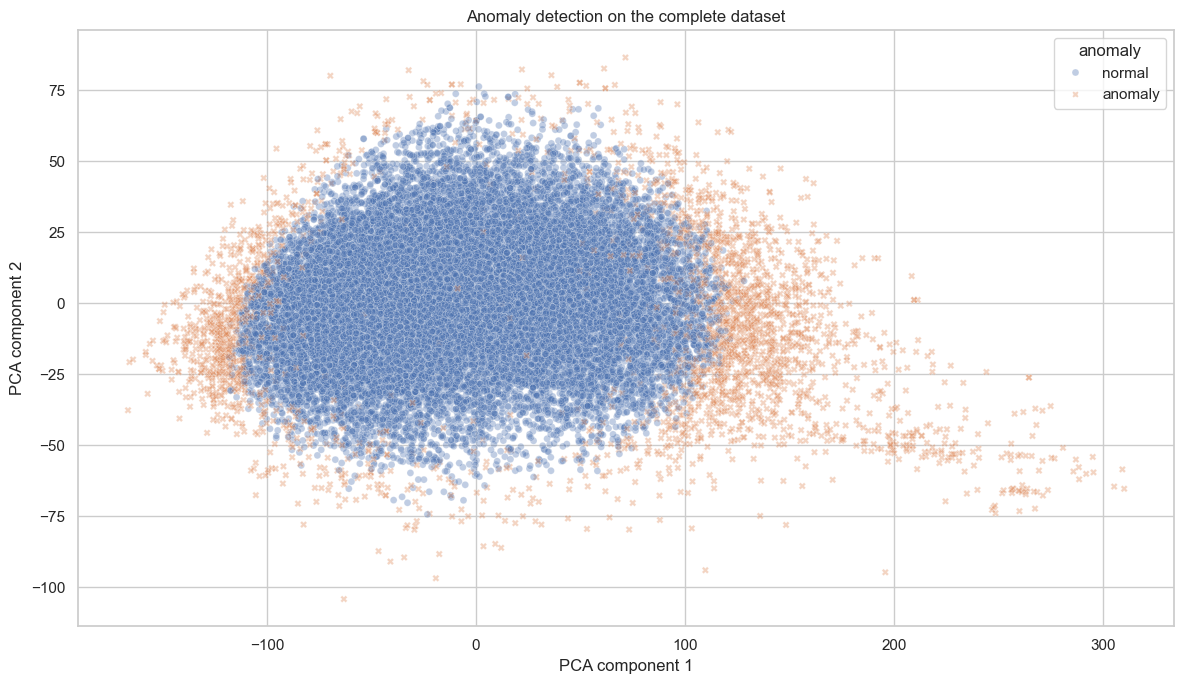

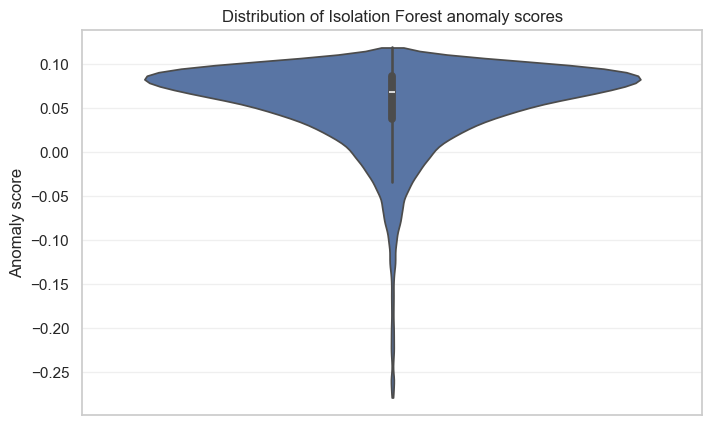

index= 23238  class=yes      score=-0.2795  path=train\audio\yes\d197e3ae_nohash_0.wav


index= 10497  class=off      score=-0.2795  path=train\audio\off\735845ab_nohash_2.wav


index=  8074  class=no       score=-0.2792  path=train\audio\no\712e4d58_nohash_4.wav


index= 25107  class=unknown  score=-0.2792  path=train\audio\wow\712e4d58_nohash_0.wav


index=  5728  class=left     score=-0.2792  path=train\audio\left\712e4d58_nohash_2.wav


index= 18905  class=stop     score=-0.2787  path=train\audio\stop\fd395b74_nohash_1.wav


index=  3375  class=go       score=-0.2781  path=train\audio\go\712e4d58_nohash_4.wav


index= 14128  class=on       score=-0.2757  path=train\audio\on\f953e1af_nohash_1.wav


index= 18120  class=stop     score=-0.2757  path=train\audio\stop\aff582a1_nohash_4.wav


index= 11041  class=off      score=-0.2757  path=train\audio\off\aff582a1_nohash_2.wav


In [15]:
plot_df = pd.DataFrame(
    {
        "pc1": feature_2d[:, 0],
        "pc2": feature_2d[:, 1],
        "label": [ID2LABEL[int(label)] for label in anomaly_labels],
        "anomaly": np.where(anomaly_flags == -1, "anomaly", "normal"),
        "score": anomaly_score,
    }
)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=plot_df,
    x="pc1",
    y="pc2",
    hue="anomaly",
    style="anomaly",
    alpha=0.35,
    s=25,
)
plt.title("Anomaly detection on the complete dataset")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.tight_layout()
plt.show()

# Find all anomalies and sort them by score.
anomaly_indices = np.where(anomaly_flags == -1)[0]
anomaly_indices = anomaly_indices[np.argsort(anomaly_score[anomaly_indices])]

plt.figure(figsize=(8, 5))
sns.violinplot(
    y=anomaly_score,
    inner="box",
    cut=0,
)
plt.title("Distribution of Isolation Forest anomaly scores")
plt.ylabel("Anomaly score")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Display the most anomalous examples. This is useful for checking whether outliers are truly unusual
# recordings or simply legitimate accents/noise/speakers that the detector considers rare.
for index in anomaly_indices[:10]:
    label = ID2LABEL[int(anomaly_labels[index])]
    path = dataset.samples[index]["path"]
    print(
        f"index={index:6d}  class={label:7s}  score={anomaly_score[index]: .4f}  path={path}"
    )
    display(Audio(dataset[index]["speech"].squeeze(0).numpy(), rate=SAMPLE_RATE))

,count
label,
yes,395
no,247
up,299
down,296
left,160
right,189
on,289
off,218
stop,242


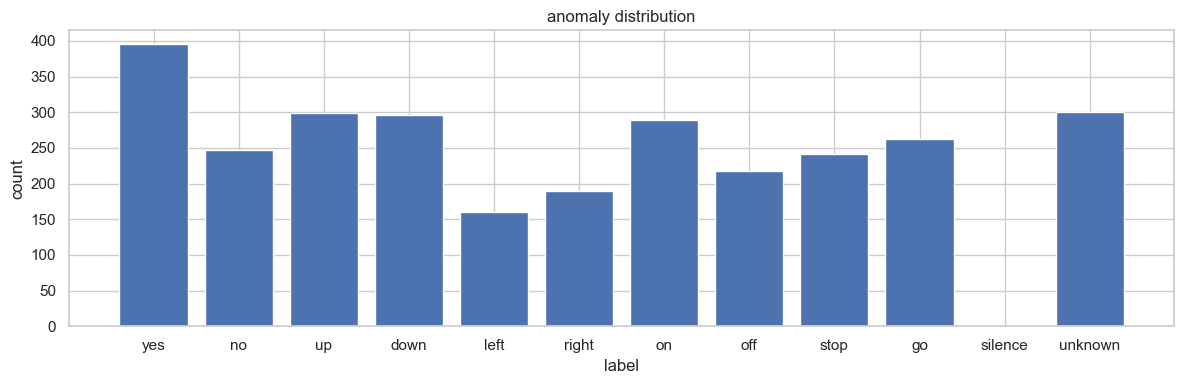

In [ ]:
anomaly_counts: pd.DataFrame = (
    plot_df.iloc[anomaly_indices]
    .groupby("label")
    .size()
    .reindex(ALL_CLASSES, fill_value=0)
    .rename("count")
    .to_frame()
)

display(anomaly_counts)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(anomaly_counts.index, anomaly_counts["count"])
ax.set_title("anomaly distribution")
ax.set_xlabel("label")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

In [17]:
threshold = np.percentile(anomaly_score, 5)

filtered_anomaly_indices = np.where(
    (anomaly_flags == -1) & (anomaly_score < threshold)
)[0]
filtered_anomaly_indices = filtered_anomaly_indices[
    np.argsort(anomaly_score[filtered_anomaly_indices])
]

print(f"Filtered anomalies: {len(filtered_anomaly_indices):,} / {len(dataset):,}")

Filtered anomalies: 1,302 / 26,035


,count
label,
yes,146
no,113
up,138
down,140
left,86
right,98
on,149
off,107
stop,102


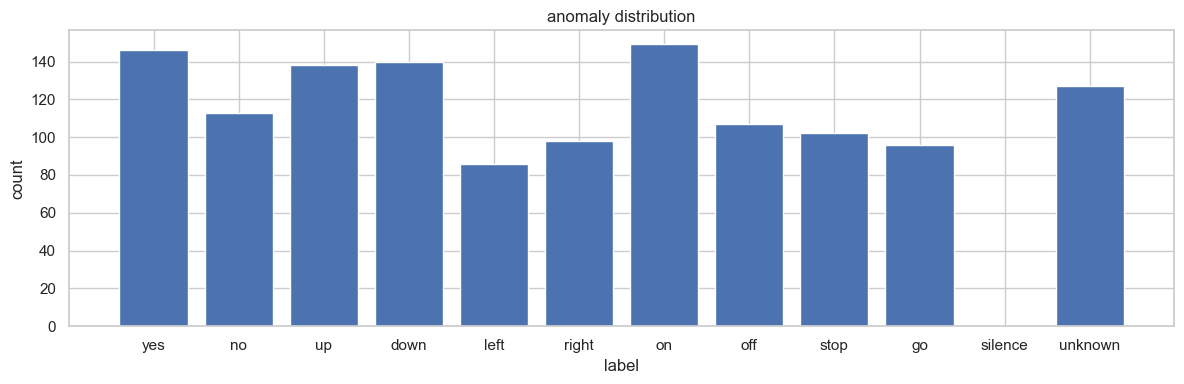

In [ ]:
filtered_anomaly_counts: pd.DataFrame = (
    plot_df.iloc[filtered_anomaly_indices]
    .groupby("label")
    .size()
    .reindex(ALL_CLASSES, fill_value=0)
    .rename("count")
    .to_frame()
)

display(filtered_anomaly_counts)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(filtered_anomaly_counts.index, filtered_anomaly_counts["count"])
ax.set_title("anomaly distribution")
ax.set_xlabel("label")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

In [ ]:
import json

anomaly_pathes = []

for index in filtered_anomaly_indices:
    label = ID2LABEL[int(anomaly_labels[index])]
    path = dataset.samples[index]["path"]
    relative = path.relative_to(dataset.audio_dir).as_posix()
    anomaly_pathes.append(str(relative))

with open("../anomalies.json", "w", encoding="utf8") as f:
    json.dump(anomaly_pathes, f, ensure_ascii=False, indent=2)

In [20]:
with_anomalies = factory.train(add_silence=True, skip_anomalies=False)
without_anomalies = factory.train(add_silence=True, skip_anomalies=True)

len(with_anomalies), len(without_anomalies)

(22216, 21049)